In [30]:
#필요한 도구 가져오기
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [31]:
# 데이터 읽어오기
df = pd.read_csv('data/manhattan.csv')
df.head()

,rental_id,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,1545,2550,0.0,1,480,9,2.0,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,2472,11500,2.0,2,2000,4,1.0,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,2919,4500,1.0,1,916,2,51.0,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,2790,4795,1.0,1,975,3,8.0,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,3946,17500,2.0,2,4800,3,4.0,136,0,0,0,1,1,1,0,1,Soho,Manhattan


In [32]:
# 입력데이터와 정답 분리
label = df['rent'].values
data = df.iloc[:,2:-2].values
data.shape

(3539, 14)

In [33]:
#훈련/테스트 데이터분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [34]:
poly = PolynomialFeatures(degree=1,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [35]:
ss =StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [36]:
#학습
lr = LinearRegression()
lr.fit(train_data,train_label)

#평가
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print(score)
print(score2)

0.7848646956193592
0.7602678524659694


In [37]:
#예측
predict = lr.predict(test_data)
print("예측방값:",predict)

예측방값: [ 5005.57781336  5552.06051959  4133.40199878  5191.47180994
  3612.74818218  2974.62329144  7256.24198346  5950.69477049
  4238.77341068  8312.12205478  3608.01678591  5696.95568501
  3957.1592368   3905.68289527  5197.01108865  3921.75875005
  3461.64956063  2801.36638249  3464.91321083  4764.06109664
  3492.36208023  9556.81041254  6030.08293914  4392.13367069
  2382.28481606  3464.39076706  6536.74775021  5163.60483479
  9050.9512817   9770.72456589  3283.1326894   3978.69875464
  4223.29379952  7488.40950919 10367.2882637   4977.276583
  2360.3632009   4371.92102305  3012.85127294 11283.23418399
  3404.39932461 12754.34299273  6461.38070366  1633.46139249
  3416.91110398  4921.21988136  6574.30579989  3994.31535788
  4585.67216687  4012.12314604 14715.14040569  9306.68924325
  4096.47638535 11672.02304728  6177.91412367  6214.48376915
  3068.15226089  2753.47876835  5223.56273596  3474.33149242
  5072.63482776  3730.01378098  2779.49591572  6874.39207513
  8241.19054578  291

In [38]:
in_data =input('침실수,욕실수,면적,지하철까지시간,층수,건물나이,중개수수료없음,옥상데크,세탁건조기,도어맨,엘리베이터,'
    '식기세척기,파티오,헬스장 순서대로 입력: 예) 1,1,700,5,3,20,1,0,1,0,1,1,0,0')

in_data = in_data.split(',')

out_data = []
for value in in_data:
    out_data.append(float(value))

if len(out_data) == 14:
    result = lr.predict([out_data])
    print(f"예상 월세:{result[0]:.2f}달러")
else:
    print("숫자 14개를 입력해주세요.")

예상 월세:3760.84달러


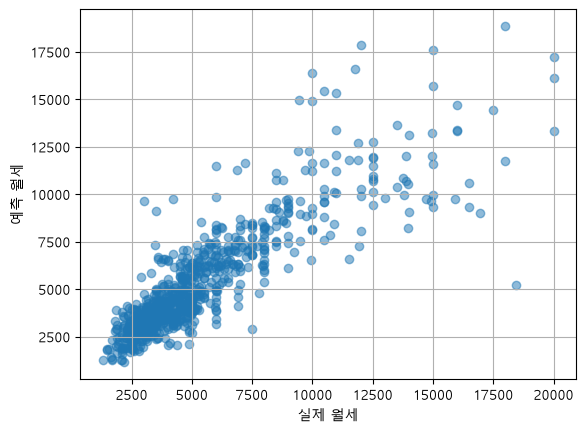

In [39]:
plt.scatter(test_label, predict, alpha=0.5)

plt.xlabel('실제 월세')
plt.ylabel('예측 월세')
plt.grid()
plt.show()